# Euler hacia adelante paso a paso, el umbral y el oráculo del tamaño final

- **Nivel:** 2, El método en la práctica
- **Prerrequisitos:** cuaderno 01 de este tema
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular a mano un paso de Euler hacia adelante y ver que es igual al del motor;
- leer $R_0 = \beta / \gamma$ como el umbral entre un brote que se apaga y uno que crece;
- resolver la relación del tamaño final y usarla como un oráculo que no depende del curso temporal;
- medir que el error del motor decrece a primer orden en el paso.

## Preparación

El entorno de los cuadernos está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este cuaderno, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica un paquete propio: su método vive en `data-pipeline/pipeline/`, así que el cuaderno importa ese código por su ruta. Un producto importa en cambio su propio paquete de PyPI (`pip install <paquete>==<versión>`).

La siguiente celda importa las herramientas e imprime sus versiones.

In [1]:
# Imprimir las versiones de las herramientas de este cuaderno, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json

import numpy as np
import matplotlib.pyplot as plt

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


Como en el cuaderno 01, el motor se importa desde `data-pipeline/` por su ruta.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; los módulos del pipeline se importan por su ruta
import sys
from pathlib import Path

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.sir import simulate
from pipeline.io.schema import SIRParams

print(simulate.__module__, SIRParams.__module__)

pipeline.model.sir pipeline.io.schema


## Datos

Los mismos cinco casos calculados del cuaderno 01.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce desde los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay conjunto de datos de terceros, así que no aplica licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json`, `data/derived/manifests/<case>.json`.

La siguiente celda define otra vez los dos lectores y lista los casos.

In [3]:
# Dos lectores de los artefactos versionados: un archivo ausente detiene el cuaderno y nombra su ruta
def read_json(relative):
    return json.loads((ROOT / "data" / "derived" / relative).read_text(encoding="utf-8"))


def params_of(case_id):
    p = read_json(f"manifests/{case_id}.json")["params"]
    return SIRParams(case_id, p["beta"], p["gamma"], p["N"], p["I0"], p["days"])


CASES = [c["case_id"] for c in read_json("manifests/index.json")["cases"]]
OUTBREAKS = [c for c in CASES if c.startswith("EX")]
SUPERCRITICAL = [c for c in OUTBREAKS if params_of(c).beta > params_of(c).gamma]
print(CASES)
print("casos que pueden despegar:", SUPERCRITICAL)

['CTRL_degenerate', 'EX01_subcritical', 'EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']
casos que pueden despegar: ['EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']


Esta celda lee los parámetros de cada caso e imprime $R_0$ junto a ellos. Los parámetros son todo lo que este cuaderno necesita de los datos.

In [4]:
# Listar los parámetros de cada caso con su cociente reproductivo básico R0 = beta / gamma
for case_id in CASES:
    p = params_of(case_id)
    print(f"{case_id:18s} beta={p.beta:.2f} gamma={p.gamma:.2f} N={p.N:.0f} I0={p.I0:.0f} R0={p.beta / p.gamma:.2f}")

CTRL_degenerate    beta=0.40 gamma=0.20 N=100000 I0=0 R0=2.00
EX01_subcritical   beta=0.18 gamma=0.25 N=100000 I0=50 R0=0.72
EX02_epidemic      beta=0.55 gamma=0.20 N=100000 I0=50 R0=2.75
EX03_fast_burn     beta=1.20 gamma=0.20 N=100000 I0=100 R0=6.00
EX04_slow_spread   beta=0.30 gamma=0.25 N=100000 I0=50 R0=1.20


## Método

### 1. Un paso de Euler hacia adelante, a mano

Euler hacia adelante avanza el estado con las tasas de su inicio, multiplicadas por el paso $\Delta t$ (Hairer, Norsett y Wanner, 1993). Para el sistema SIR, con $S_k, I_k, R_k$ el estado tras $k$ pasos:

$$\Delta_{inf} = \beta \frac{S_k I_k}{N} \Delta t, \quad \Delta_{rec} = \gamma I_k \Delta t, \quad S_{k+1} = S_k - \Delta_{inf}, \quad I_{k+1} = I_k + \Delta_{inf} - \Delta_{rec}, \quad R_{k+1} = R_k + \Delta_{rec}$$

Esta celda calcula a mano el primer paso del caso de epidemia, solo para leer lo que hace el motor, y lo compara con el primer paso de la corrida del propio motor. La corrida completa sigue en `simulate`: el cuaderno no la reimplementa.

In [5]:
# Un paso a mano desde el estado inicial, y luego el primer paso del motor para comparar
p = params_of("EX02_epidemic")
dt = 0.25
S0, I0, R_start = p.N - p.I0, p.I0, 0.0
new_infections = p.beta / p.N * S0 * I0 * dt
new_recoveries = p.gamma * I0 * dt
by_hand = (S0 - new_infections, I0 + new_infections - new_recoveries, R_start + new_recoveries)

run = simulate(p)
engine = (run.S[1], run.I[1], run.R[1])
print("nuevas infecciones:", round(new_infections, 4), "| nuevas recuperaciones:", round(new_recoveries, 4))
print("a mano:", [round(v, 4) for v in by_hand])
print("motor: ", [round(v, 4) for v in engine])
print("iguales:", bool(np.allclose(by_hand, engine)))

nuevas infecciones: 6.8716 | nuevas recuperaciones: 2.5
a mano: [99943.1284, 54.3716, 2.5]
motor:  [99943.1284, 54.3716, 2.5]
iguales: True


### 2. El umbral R0 = beta / gamma

$R_0$ es el cociente reproductivo básico: el número medio de personas que una persona infectada contagia en una población totalmente susceptible (Diekmann, Heesterbeek y Metz, 1990). Para los modelos compartimentales, $R_0 < 1$ es la condición de estabilidad del estado libre de enfermedad (van den Driessche y Watmough, 2002): un brote se apaga. Esta celda corre cada caso con el motor y compara el pico de infectados con los infectados iniciales, junto a $R_0$.

In [6]:
# Correr cada caso y comparar el pico de infectados con los infectados iniciales
for case_id in CASES:
    p = params_of(case_id)
    r = simulate(p)
    r0 = p.beta / p.gamma
    grows = r.peak_I > p.I0 * 1.000001
    print(f"{case_id:18s} R0={r0:4.2f}  I0={p.I0:5.0f}  pico={r.peak_I:9.1f} el día {r.t_peak:6.2f}  crece={grows}")

CTRL_degenerate    R0=2.00  I0=    0  pico=      0.0 el día   0.00  crece=False
EX01_subcritical   R0=0.72  I0=   50  pico=     50.0 el día   0.00  crece=False
EX02_epidemic      R0=2.75  I0=   50  pico=  27345.2 el día  24.25  crece=True
EX03_fast_burn     R0=6.00  I0=  100  pico=  55265.1 el día   9.25  crece=True
EX04_slow_spread   R0=1.20  I0=   50  pico=   1520.8 el día  96.25  crece=True


### 3. El tamaño final como oráculo

Sea cual sea el curso temporal, la fracción $z$ de la población que llega a infectarse resuelve la relación del tamaño final (Kermack y McKendrick, 1927; Miller, 2012):

$$z = 1 - e^{-R_0 z}$$

Para $R_0 \le 1$ la única solución es $z = 0$. Esta celda la resuelve por iteración de punto fijo, un oráculo que no comparte código con el motor, y la compara con la tasa de ataque que reporta el motor. La relación vale para una corrida que termina dentro de su horizonte, así que la celda imprime también la parte de la población que sigue infectada en el horizonte.

In [7]:
# Resolver z = 1 - exp(-R0 z) por iteración de punto fijo y comparar con la tasa de ataque del motor
def final_size(r0, tolerance=1e-12):
    z = 1.0
    for _ in range(100_000):
        z_next = 1.0 - np.exp(-r0 * z)
        if abs(z_next - z) < tolerance:
            return z_next
        z = z_next
    return z


print(f"{'case':18s} {'R0':>5s} {'z':>8s} {'motor':>8s} {'diff':>8s} {'aún infectados':>15s}")
for case_id in CASES:
    p = params_of(case_id)
    r = simulate(p)
    z = final_size(p.beta / p.gamma)
    print(f"{case_id:18s} {p.beta / p.gamma:5.2f} {z:8.4f} {r.attack_rate:8.4f} {r.attack_rate - z:8.4f} {r.I[-1] / p.N:15.6f}")

case                  R0        z    motor     diff  aún infectados
CTRL_degenerate     2.00   0.7968   0.0000  -0.7968        0.000000
EX01_subcritical    0.72   0.0000   0.0018   0.0018        0.000000
EX02_epidemic       2.75   0.9204   0.9237   0.0032        0.000000
EX03_fast_burn      6.00   0.9975   0.9982   0.0007        0.000000
EX04_slow_spread    1.20   0.3137   0.2993  -0.0144        0.002890


### 4. Convergencia de primer orden en el paso

El error global de Euler hacia adelante es de primer orden en el paso (Hairer, Norsett y Wanner, 1993): reducir $\Delta t$ a la mitad reduce el error a la mitad. Sin una solución exacta a mano, esta celda corre el motor con pasos de 1, 1/2, 1/4, 1/8 y 1/16 de día, toma las diferencias entre resultados consecutivos y estima el orden observado como $\log_2$ del cociente de diferencias consecutivas. Un orden cercano a 1 es de primer orden.

dt= 1.0000  tasa de ataque=0.300894
dt= 0.5000  tasa de ataque=0.299818
dt= 0.2500  tasa de ataque=0.299285
dt= 0.1250  tasa de ataque=0.299019
dt= 0.0625  tasa de ataque=0.298887
diferencias entre pasos consecutivos: ['0.001076', '0.000533', '0.000265', '0.000132']
orden observado: [1.01, 1.01, 1.0]


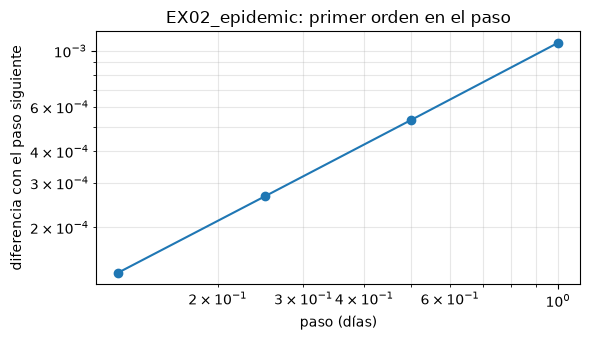

In [8]:
# Correr el motor con cinco pasos, diferenciar las tasas de ataque y estimar el orden observado
steps = [1.0, 0.5, 0.25, 0.125, 0.0625]
attack = [simulate(p, dt=h).attack_rate for h in steps]
diffs = np.abs(np.diff(attack))
orders = np.log2(diffs[:-1] / diffs[1:])

for h, a in zip(steps, attack):
    print(f"dt={h:7.4f}  tasa de ataque={a:.6f}")
print("diferencias entre pasos consecutivos:", [f"{d:.6f}" for d in diffs])
print("orden observado:", [round(float(o), 2) for o in orders])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(steps[:-1], diffs, "o-")
ax.set_xlabel("paso (días)")
ax.set_ylabel("diferencia con el paso siguiente")
ax.set_title("EX02_epidemic: primer orden en el paso")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

## Resultados

Lo que muestran las celdas, en orden:

1. El paso calculado a mano es igual al primer paso del motor: el motor es la regla de actualización de arriba, nada más.
2. El caso subcrítico (R0 bajo 1) nunca supera sus infectados iniciales; todo caso con R0 sobre 1 crece hasta un pico. El control, sin infección inicial, no tiene nada que crezca, sea cual sea su R0.
3. Para los casos de epidemia y de combustión rápida la relación del tamaño final coincide con la tasa de ataque del motor dentro de unas milésimas, y el valor del motor es el mayor: Euler hacia adelante con paso de un cuarto de día se pasa un poco. El caso de propagación lenta aún tiene gente infectada en el horizonte (la última columna), así que la relación no le aplica y su tasa de ataque queda bajo $z$; es el límite del oráculo, no un error del motor. El control, sin infección inicial, no tiene nada que propagar, así que la solución no trivial de la relación no le aplica (su fila muestra el motor en cero). La relación de aquí es la de una infección inicial que tiende a cero; el siguiente tema la refina.
4. Las diferencias entre pasos consecutivos se reducen a la mitad cada vez que el paso se reduce a la mitad, y los órdenes observados están cerca de 1: el motor converge a primer orden, como predice el método. La figura muestra las diferencias cayendo sobre una recta de pendiente 1 en ejes logarítmicos.

## Resumen

- Euler hacia adelante es una regla de actualización aplicada 640 veces; el motor implementa exactamente eso.
- $R_0 = \beta / \gamma$ separa los casos que se apagan de los que despegan.
- La relación del tamaño final es un oráculo independiente del curso temporal, válido para una corrida que termina dentro de su horizonte.
- El error del motor cae a primer orden en el paso.
- Siguiente: el tema 02 usa el umbral y el tamaño final por sí solos, y los compara con el estado del arte.

## Referencias

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Diekmann, O., Heesterbeek, J. A. P. and Metz, J. A. J. (1990). On the definition and the computation of the basic reproduction ratio R0 in models for infectious diseases in heterogeneous populations. Journal of Mathematical Biology. https://doi.org/10.1007/BF00178324
- van den Driessche, P. and Watmough, J. (2002). Reproduction numbers and sub-threshold endemic equilibria for compartmental models of disease transmission. Mathematical Biosciences. https://doi.org/10.1016/S0025-5564(02)00108-6
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- El motor y los casos de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).

Lo que se atribuye a cada obra es lo que registra la base de investigación del SDD (`docs/design/SDD.md`); el texto de sus páginas no se volvió a leer, solo sus registros de Crossref.